In [1]:
from pathlib import Path
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

WHITEBOARD_PATH = PROJECT_ROOT / "datasets" / "whiteboard"

print("Dataset path:", WHITEBOARD_PATH)
print("Dataset exists:", WHITEBOARD_PATH.exists())


Dataset path: c:\Users\rohit\OneDrive\Desktop\BoardMindAI\datasets\whiteboard
Dataset exists: True


In [2]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

splits = ["train", "valid", "test"]

for split in splits:

    image_dir = WHITEBOARD_PATH / split / "images"
    label_dir = WHITEBOARD_PATH / split / "labels"

    images = [
        f for f in image_dir.iterdir()
        if f.suffix.lower() in image_extensions
    ]

    labels = list(label_dir.glob("*.txt"))

    image_names = {f.stem for f in images}
    label_names = {f.stem for f in labels}

    missing_labels = image_names - label_names
    extra_labels = label_names - image_names

    print(f"\n{split.upper()} DATASET")
    print("-" * 35)
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(extra_labels))


TRAIN DATASET
-----------------------------------
Images: 1608
Labels: 1608
Images without labels: 0
Labels without images: 0

VALID DATASET
-----------------------------------
Images: 179
Labels: 179
Images without labels: 0
Labels without images: 0

TEST DATASET
-----------------------------------
Images: 177
Labels: 177
Images without labels: 0
Labels without images: 0


In [3]:
def validate_yolo_segmentation(split):

    label_dir = WHITEBOARD_PATH / split / "labels"

    valid_count = 0
    invalid_count = 0
    empty_count = 0

    for label_file in label_dir.glob("*.txt"):

        lines = label_file.read_text().strip().splitlines()

        if not lines or not any(line.strip() for line in lines):
            empty_count += 1
            continue

        for line in lines:

            values = line.split()

            try:
                values = list(map(float, values))

                # Class ID + polygon coordinates
                if len(values) < 7:
                    raise ValueError("Too few coordinates")

                coordinates = values[1:]

                if len(coordinates) % 2 != 0:
                    raise ValueError("Odd number of coordinates")

                if len(coordinates) < 6:
                    raise ValueError("Less than 3 polygon points")

                if not all(np.isfinite(v) for v in values):
                    raise ValueError("Non-finite values")

                if values[0] < 0 or not values[0].is_integer():
                    raise ValueError("Invalid class ID")

                if not all(0 <= v <= 1 for v in coordinates):
                    raise ValueError("Coordinates outside 0-1")

                valid_count += 1

            except ValueError as error:
                invalid_count += 1
                print(f"Problem in {label_file.name}: {error}")

    print(f"\n{split.upper()} ANNOTATION REPORT")
    print("Valid polygons:", valid_count)
    print("Invalid polygons:", invalid_count)
    print("Empty annotation files:", empty_count)


for split in splits:
    validate_yolo_segmentation(split)

Problem in 1-609-_jpg.rf.178c27ed5fa38e6c6d94b76defd40df2.txt: Too few coordinates
Problem in 1-609-_jpg.rf.28f083f9f30eb629b1008c34d30fe9df.txt: Too few coordinates
Problem in 1-609-_jpg.rf.e0507d8e660b60ef77d719fc1ac4c6df.txt: Too few coordinates
Problem in Capture_PNG.rf.3829e23e6c161efe8d612586e78d5f9a.txt: Too few coordinates
Problem in Capture_PNG.rf.c9130257bbeb4ff3c23396fefa250efa.txt: Too few coordinates
Problem in Capture_PNG.rf.f80a28811af38eacad92fd8a2db66845.txt: Too few coordinates
Problem in images-3-_jpg.rf.03c5738bac51df5c2dbea4095523318b.txt: Too few coordinates
Problem in images-3-_jpg.rf.9a5261b3f34a5848475f947ff3dd50f7.txt: Too few coordinates
Problem in images-3-_jpg.rf.eaaea922255adf93b3be0b2030d6adf0.txt: Too few coordinates
Problem in images-4-_jpg.rf.781c8135b53ac6238b731e99d065bd6a.txt: Too few coordinates
Problem in images-4-_jpg.rf.eebe6f79c359bddd2758b9e6bdd23a33.txt: Too few coordinates
Problem in images-4-_jpg.rf.f4ec4a5bc0ebf78c90c53d6ef5d829a1.txt: Too

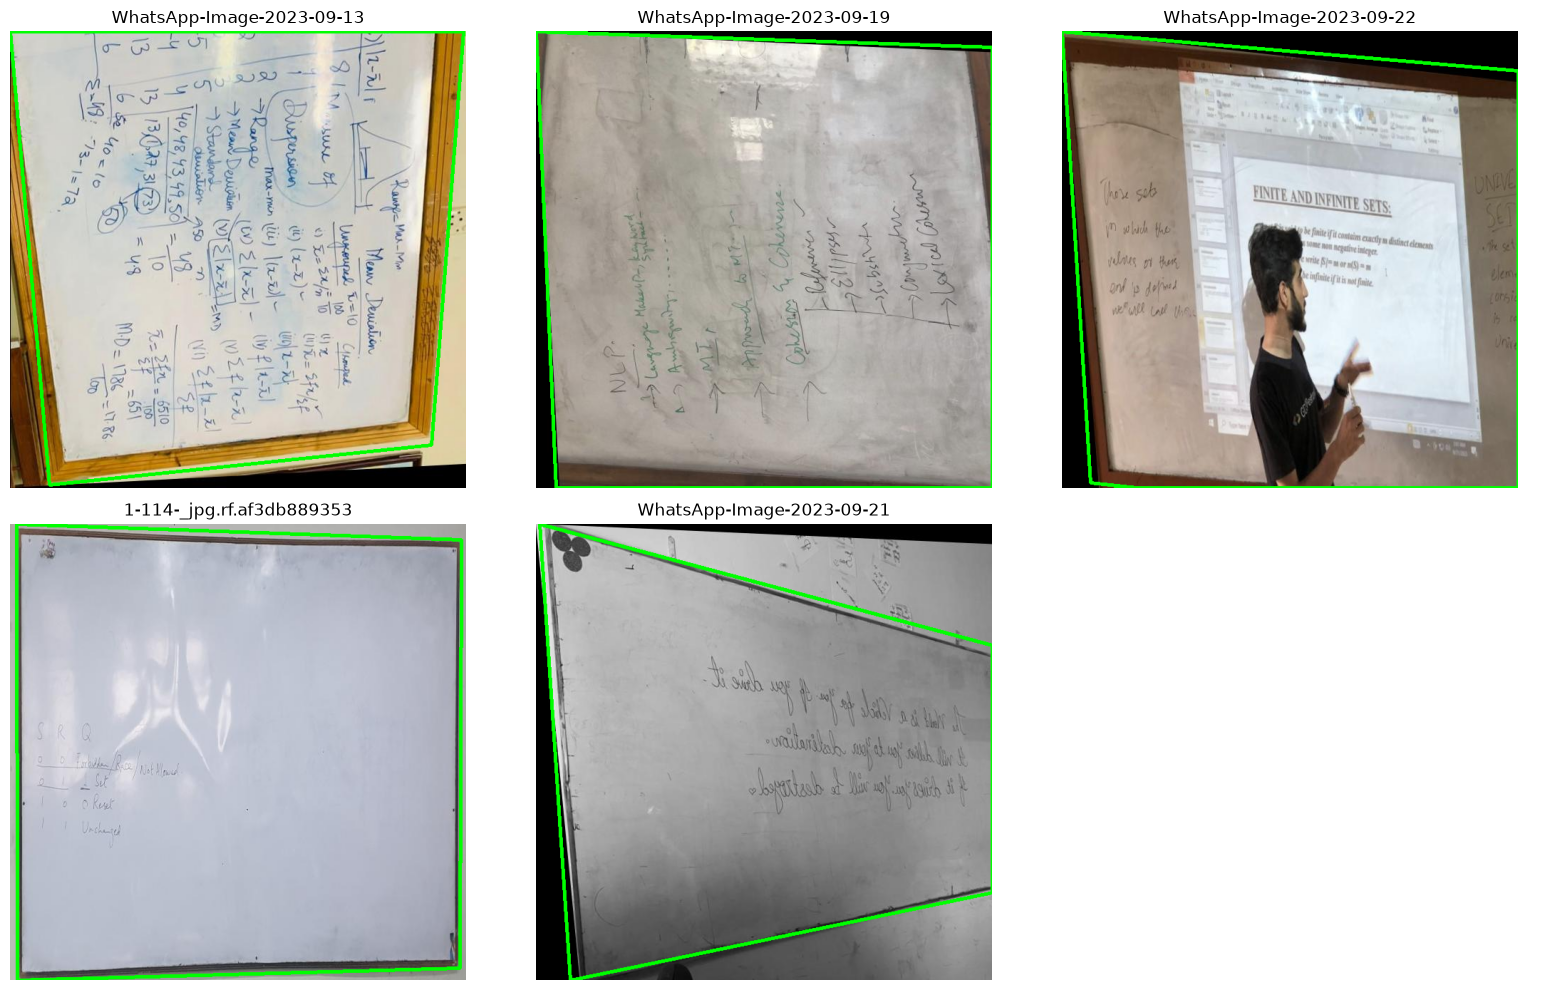

In [4]:
import random

train_images = WHITEBOARD_PATH / "train" / "images"
train_labels = WHITEBOARD_PATH / "train" / "labels"

image_files = [
    f for f in train_images.iterdir()
    if f.suffix.lower() in image_extensions
]

selected_images = random.sample(
    image_files,
    min(5, len(image_files))
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, selected_images):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    label_path = train_labels / f"{image_path.stem}.txt"

    if label_path.exists():

        for line in label_path.read_text().splitlines():

            values = list(map(float, line.split()))

            points = np.array(values[1:]).reshape(-1, 2)

            points[:, 0] *= width
            points[:, 1] *= height

            points = points.astype(np.int32)

            cv2.polylines(
                image,
                [points],
                True,
                (0, 255, 0),
                3
            )

    ax.imshow(image)
    ax.set_title(image_path.name[:25])
    ax.axis("off")

for ax in axes[len(selected_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
yaml_path = WHITEBOARD_PATH / "data.yaml"

with open(yaml_path, "r") as file:
    dataset_config = yaml.safe_load(file)

print(dataset_config)

{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['Whiteboard'], 'roboflow': {'workspace': 'university-of-peshawar-4qet5', 'project': 'whiteboard-dataset', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/university-of-peshawar-4qet5/whiteboard-dataset/dataset/1'}}


In [6]:
import ultralytics
import torch

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\rohit\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.204
PyTorch: 2.15.0+cpu
CUDA available: False
Using CPU
